# External validation on VinDr-CXR
Frozen Stage 2 model (5 fold checkpoints + per-fold LightGBM, score head, blend weight and tau from the RSNA run) applied to a new dataset. Nothing is retrained or retuned here.

Inputs to attach to this notebook:
1. Output of the RSNA training notebook (`final_model_config.json`, `raddino_fold*.pt`, `fold*_tabular.joblib`).
2. The VinDr-CXR images as PNG/JPG (file name = image id) and their annotation CSV.
3. Stage 1 detector proposals on those same images (`patientId, confidence, pred_x1, pred_y1, pred_x2, pred_y2`).

In [1]:
!pip install -q transformers accelerate scikit-learn opencv-python-headless lightgbm

## 1. Setup (identical Config to the RSNA training run)

In [7]:
import gc, glob, hashlib, json, math, os, random, time, warnings
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, replace
from typing import Optional

import cv2
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from torch.optim.swa_utils import AveragedModel
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModel

warnings.filterwarnings("ignore")


@dataclass(frozen=True)
class Config:
    seed: int = 42
    work_dir: str = "/kaggle/working"

    # proposals; IoU in [iou_ignore_lo, iou_tp) is ambiguous: excluded from BCE, kept for the IoU auxiliary loss
    conf_cutoff: float = 0.15
    iou_tp: float = 0.40
    iou_ignore_lo: float = 0.20
    use_det_features: bool = True
    box_coord_size: Optional[int] = None  # None: boxes are already in each image's pixel space

    # crops
    local_pad: float = 0.15
    ctx_scale: float = 2.5
    ctx_min_px: int = 192
    img_size: int = 240

    # model
    model_name: str = "microsoft/rad-dino"
    head_dim: int = 256
    head_dropout: float = 0.3
    drop_path: float = 0.1
    use_grad_ckpt: bool = False
    p_tab_drop: float = 0.30        # modality dropout forces the pixel path to carry signal
    p_view_drop: float = 0.10

    # optimisation
    batch_size: int = 24
    eval_bs: int = 64
    epochs: int = 10
    patience: int = 5
    backbone_lr: float = 2e-5           # or 1e-5
    llrd: float = 0.80                  # 0.7
    head_lr: float = 5e-4
    weight_decay: float = 0.05
    warmup_frac: float = 0.1
    ema_decay: float = 0.995
    grad_clip: float = 1.0
    freeze_epochs: float = 0.4  # head-only warm-up with the backbone under no_grad
    aux_w: float = 1.0

    # augmentation: geometry is kept mild because the label is IoU-based
    aug_rot: float = 10.0
    aug_scale: float = 0.10
    aug_shift: float = 0.06
    flip_p: float = 0.5

    # evaluation
    target_recall: float = 0.90
    n_folds: int = 5
    val_frac: float = 0.15
    run_folds: tuple = (0, 1, 2, 3, 4)  # e.g. (0,) for a smoke test; finished folds are cached and skipped
    n_boot: int = 300


LGBM_PARAMS = dict(n_estimators=800, learning_rate=0.02, max_depth=6, num_leaves=31, subsample=0.8,
                   subsample_freq=1, colsample_bytree=0.8, class_weight="balanced", verbose=-1,
                   min_child_samples=40, reg_lambda=5)

CFG = Config()
OUT_DIR = os.path.join(CFG.work_dir, "external_vindr")
os.makedirs(OUT_DIR, exist_ok=True)
# fold caches are keyed by config, so changing a hyperparameter can never silently reuse stale predictions
RUN_TAG = hashlib.md5(repr((replace(CFG, run_folds=()), LGBM_PARAMS)).encode()).hexdigest()[:8]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def autocast():
    return torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda")


seed_all(CFG.seed)
torch.backends.cudnn.benchmark = True
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cuda Tesla T4


In [22]:
@dataclass(frozen=True)
class ExternalConfig:
    proposals_csv: str = "/kaggle/input/notebooks/prahlad214/rtdetr-vindrcxr/vindr_proposals.csv"
    annotations_csv: str = "/kaggle/input/competitions/vinbigdata-chest-xray-abnormalities-detection/train.csv"
    meta_csv: Optional[str] = "/kaggle/input/datasets/xhlulu/vinbigdata-chest-xray-resized-png-1024x1024/train_meta.csv"
    artifacts_glob: str = "/kaggle/input/**/final_model_config.json"
    positive_classes: tuple = ("Consolidation", "Infiltration", "Lung Opacity")
    min_agree: int = 2
    consensus_iou: float = 0.4


XCFG = ExternalConfig()

In [20]:
!find /kaggle/input -name "train.csv"

/kaggle/input/competitions/vinbigdata-chest-xray-abnormalities-detection/train.csv


## 2. Trained artifacts

In [10]:
def locate_artifacts(cfg, xcfg):
    found = glob.glob(xcfg.artifacts_glob, recursive=True)
    if not found:
        raise FileNotFoundError("final_model_config.json not found - attach the RSNA training notebook's output as an input.")
    art_dir = os.path.dirname(found[0])
    tags = {os.path.basename(p).split("_")[1] for p in glob.glob(os.path.join(art_dir, "fold0_*_tabular.joblib"))}
    if len(tags) != 1:
        raise RuntimeError(f"expected exactly one run tag in {art_dir}, found {sorted(tags)}")
    tag = tags.pop()
    if tag != RUN_TAG:
        print(f"WARNING: Config differs from the training run ({tag} vs {RUN_TAG}); crop size, model or LightGBM params may not match.")
    paths = {k: dict(pt=os.path.join(art_dir, f"raddino_fold{k}_{tag}.pt"),
                     tab=os.path.join(art_dir, f"fold{k}_{tag}_tabular.joblib")) for k in cfg.run_folds}
    missing = [p for d in paths.values() for p in d.values() if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError(f"missing artifacts: {missing}")
    final = json.load(open(found[0]))
    print("artifacts:", art_dir, "| tag", tag, "|", final)
    return paths, final


ARTIFACTS, FINAL = locate_artifacts(CFG, XCFG)

artifacts: /kaggle/input/notebooks/prahlad214/rsna-project/experiments/raddino_cv | tag 9b0dcdd1 | {'score_head': 'tp', 'verifier_weight': 0.7000000000000001, 'tau': -0.03715704733271331, 'verifier_mean': -2.474928140640259, 'verifier_std': 2.160935163497925, 'lgbm_logit_mean': -2.427522225639041, 'lgbm_logit_std': 2.477518363671044}


## 3. Stage 1 proposals on the new dataset

In [11]:
def pick_column(df, *names):
    for name in names:
        if name in df.columns:
            return name
    raise KeyError(f"None of {names} in {list(df.columns)}")


def load_detector_proposals(path, cfg):
    df = pd.read_csv(path)
    df["patientId"] = df[pick_column(df, "patientId", "image_id")].astype(str)
    df["conf"] = df[pick_column(df, "confidence", "detector_confidence")].astype(float)
    for col, aliases in dict(bx1=("pred_x1", "x1"), by1=("pred_y1", "y1"), bx2=("pred_x2", "x2"), by2=("pred_y2", "y2")).items():
        df[col] = df[pick_column(df, *aliases)].astype(float)
    n_raw = len(df)
    df = df[(df.conf >= cfg.conf_cutoff) & (df.bx2 > df.bx1) & (df.by2 > df.by1)]
    df = df.drop_duplicates(subset=["patientId", "bx1", "by1", "bx2", "by2"]).reset_index(drop=True)
    print(f"proposals {len(df)}/{n_raw} | images {df.patientId.nunique()} | proposals/image {len(df) / df.patientId.nunique():.1f}")
    return df


df = load_detector_proposals(XCFG.proposals_csv, CFG)

proposals 8361/8361 | images 3467 | proposals/image 2.4


## 4. Crops and tabular features

In [12]:
def build_image_index(patient_ids):
    index, need = {}, set(patient_ids)
    for root in ("/kaggle/input", CFG.work_dir):
        for dirpath, _, files in os.walk(root):
            for f in files:
                stem, ext = os.path.splitext(f)
                if stem in need and stem not in index and ext.lower() in (".jpg", ".jpeg", ".png"):
                    index[stem] = os.path.join(dirpath, f)
            if len(index) == len(need):
                return index
    return index


def safe_crop(img, x1, y1, x2, y2):
    # zero-pads the part of the window that falls outside the image
    H, W = img.shape
    x1, y1, x2, y2 = (int(round(v)) for v in (x1, y1, x2, y2))
    if x2 <= x1 or y2 <= y1:
        return None
    sub = img[max(0, y1):min(H, y2), max(0, x1):min(W, x2)]
    if sub.size == 0:
        return None
    return cv2.copyMakeBorder(sub, max(0, -y1), max(0, y2 - H), max(0, -x1), max(0, x2 - W), cv2.BORDER_CONSTANT, value=0)


def make_views(img, x1, y1, x2, y2, cfg):
    w, h = x2 - x1, y2 - y1
    local = safe_crop(img, x1 - w * cfg.local_pad, y1 - h * cfg.local_pad, x2 + w * cfg.local_pad, y2 + h * cfg.local_pad)
    side = max(max(w, h) * cfg.ctx_scale, cfg.ctx_min_px)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    context = safe_crop(img, cx - side / 2, cy - side / 2, cx + side / 2, cy + side / 2)
    if local is None or context is None:
        return None

    def resize(a):
        interp = cv2.INTER_AREA if a.shape[0] > cfg.img_size else cv2.INTER_LINEAR
        return cv2.resize(a, (cfg.img_size, cfg.img_size), interpolation=interp)

    return np.stack([resize(local), resize(context)])


def extract_crops(df, cfg):
    index = build_image_index(set(df.patientId))
    print("images found:", len(index), "/", df.patientId.nunique())
    crops = np.zeros((len(df), 2, cfg.img_size, cfg.img_size), np.uint8)
    img_wh = np.zeros((len(df), 2), np.float32)
    valid = np.zeros(len(df), bool)

    def crop_patient(item):
        pid, group = item
        path = index.get(pid)
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE) if path else None
        if img is None:
            return []
        H, W = img.shape
        sx, sy = (W / cfg.box_coord_size, H / cfg.box_coord_size) if cfg.box_coord_size else (1.0, 1.0)
        out = []
        for i, x1, y1, x2, y2 in zip(group.index, group.bx1, group.by1, group.bx2, group.by2):
            views = make_views(img, x1 * sx, y1 * sy, x2 * sx, y2 * sy, cfg)
            if views is not None:
                out.append((i, views, W / sx, H / sy))
        return out

    with ThreadPoolExecutor(8) as ex:
        for result in tqdm(ex.map(crop_patient, list(df.groupby("patientId"))), total=df.patientId.nunique(), desc="crops"):
            for i, views, w, h in result:
                crops[i], img_wh[i], valid[i] = views, (w, h), True
    return crops, img_wh, valid


def load_crops(df, cfg):
    params = str((cfg.local_pad, cfg.ctx_scale, cfg.ctx_min_px, cfg.img_size, cfg.box_coord_size)).encode()
    key = hashlib.md5(df[["bx1", "by1", "bx2", "by2"]].values.tobytes() + params).hexdigest()[:10]
    cache = os.path.join(OUT_DIR, f"crops_{key}.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        crops, img_wh, valid = z["crops"], z["wh"], z["valid"]
        print("[CACHE HIT]", cache)
    else:
        crops, img_wh, valid = extract_crops(df, cfg)
        np.savez(cache, crops=crops, wh=img_wh, valid=valid)

    n_missing = (~valid).sum()
    print(f"valid crops {valid.sum()}/{len(valid)} (missing {n_missing})")
    if n_missing / len(valid) > 0.01:
        raise RuntimeError("More than 1% of crops missing - fix image paths / box scale before training.")
    df, crops, img_wh = df[valid].reset_index(drop=True), crops[valid], img_wh[valid]

    assert (crops.reshape(len(df), -1).max(1) > 0).all(), "black crops present"
    out_of_image = ((df.bx2.values > img_wh[:, 0] * 1.01) | (df.by2.values > img_wh[:, 1] * 1.01)).mean()
    if out_of_image > 0.01:
        raise RuntimeError(f"{out_of_image:.1%} of boxes fall outside the image -> wrong box coordinate space (set box_coord_size).")
    return df, crops, img_wh


df, crops_np, img_wh = load_crops(df, CFG)

images found: 3467 / 3467


crops:   0%|          | 0/3467 [00:00<?, ?it/s]

valid crops 8361/8361 (missing 0)


In [13]:
def iou_matrix(boxes):
    x1 = np.maximum(boxes[:, None, 0], boxes[None, :, 0]); y1 = np.maximum(boxes[:, None, 1], boxes[None, :, 1])
    x2 = np.minimum(boxes[:, None, 2], boxes[None, :, 2]); y2 = np.minimum(boxes[:, None, 3], boxes[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (area[:, None] + area[None, :] - inter + 1e-9)


def geometry_features(df, img_wh):
    W, H = img_wh[:, 0], img_wh[:, 1]
    nx1, ny1 = np.clip(df.bx1.values / W, 0, 1), np.clip(df.by1.values / H, 0, 1)
    nx2, ny2 = np.clip(df.bx2.values / W, 0, 1), np.clip(df.by2.values / H, 0, 1)
    w, h = np.clip(nx2 - nx1, 1e-4, 1), np.clip(ny2 - ny1, 1e-4, 1)
    cx, cy = (nx1 + nx2) / 2, (ny1 + ny2) / 2
    log_aspect, log_side = np.log((w * W) / (h * H)), np.log(np.maximum(w * W, h * H))
    return np.stack([nx1, ny1, nx2, ny2, cx, cy, w, h, w * h, np.abs(cx - 0.5), log_aspect, log_side], 1).astype(np.float32)


def detector_context_features(df):
    stats = np.zeros((len(df), 8), np.float32)
    for _, group in df.groupby("patientId"):
        idx, conf = group.index.values, group.conf.values
        boxes, n = group[["bx1", "by1", "bx2", "by2"]].values, len(idx)
        rank = np.empty(n); rank[np.argsort(-conf)] = np.arange(n)
        iou = iou_matrix(boxes); np.fill_diagonal(iou, 0)
        higher = conf[None, :] > conf[:, None]
        agreement = ((iou > 0.3) * conf[None, :]).sum(1)
        stats[idx] = np.stack([rank, np.full(n, n), np.full(n, conf.max()), conf / conf.max(),
                               (iou * higher).max(1), (iou > 0.3).sum(1), agreement, rank / max(n - 1, 1)], 1)
    c = np.clip(df.conf.values, 1e-4, 1 - 1e-4)
    return np.column_stack([c, np.log(c / (1 - c)), np.log1p(stats[:, 0]), np.log1p(stats[:, 1]), stats[:, 2], stats[:, 3],
                            stats[:, 4], stats[:, 5], np.log1p(stats[:, 6]), stats[:, 7]]).astype(np.float32)


def build_tabular(df, img_wh, cfg):
    geometry = geometry_features(df, img_wh)
    return np.hstack([geometry, detector_context_features(df)]) if cfg.use_det_features else geometry


tab_raw = build_tabular(df, img_wh, CFG)
print("tabular dim:", tab_raw.shape[1])

tabular dim: 22


## Ground truth and labels
Boxes of the positive classes are fused across radiologists (a box needs `min_agree` distinct radiologists with IoU >= `consensus_iou`; coordinates are averaged).
A proposal is a TP if its best IoU with a fused box is >= `iou_tp`, exactly as in the RSNA run.

In [23]:
def pairwise_iou(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def fuse_annotations(ann, classes, min_agree, iou_thr):
    rows = []
    positive = ann[ann.class_name.isin(classes)]
    for (image_id, cls), g in positive.groupby(["image_id", "class_name"]):
        boxes, rads = g[["x_min", "y_min", "x_max", "y_max"]].values.astype(float), g.rad_id.values
        iou, used = pairwise_iou(boxes, boxes), np.zeros(len(g), bool)
        for i in range(len(g)):
            if used[i]:
                continue
            members, seen = [i], {rads[i]}
            for j in range(i + 1, len(g)):
                if not used[j] and rads[j] not in seen and iou[i, j] >= iou_thr:
                    members.append(j); seen.add(rads[j])
            used[members] = True
            if len(seen) >= min_agree:
                rows.append((image_id, cls, *boxes[members].mean(0)))
    return pd.DataFrame(rows, columns=["image_id", "cls", "x1", "y1", "x2", "y2"])


def attach_labels(df, img_wh, gt, meta, iou_tp):
    df = df.copy()
    df["iou"], df["gt_class"] = 0.0, ""
    gt_by_image = {k: g for k, g in gt.groupby("image_id")}
    for pid, g in df.groupby("patientId"):
        gg = gt_by_image.get(pid)
        if gg is None:
            continue
        boxes = gg[["x1", "y1", "x2", "y2"]].values.astype(float)
        if meta is not None:
            w0, h0 = meta[pid]
            w, h = img_wh[g.index[0]]
            boxes = boxes * np.array([w / w0, h / h0, w / w0, h / h0])
        iou = pairwise_iou(g[["bx1", "by1", "bx2", "by2"]].values, boxes)
        df.loc[g.index, "iou"] = iou.max(1)
        df.loc[g.index, "gt_class"] = gg["cls"].values[iou.argmax(1)]
    df["is_tp"] = (df.iou >= iou_tp).astype(int)
    df["is_fp"] = 1 - df.is_tp
    df.loc[df.is_tp == 0, "gt_class"] = ""
    return df


def load_ground_truth(xcfg):
    ann = pd.read_csv(xcfg.annotations_csv)
    ann["image_id"] = ann["image_id"].astype(str)
    if "rad_id" not in ann.columns:
        ann["rad_id"] = "R0"
    gt = fuse_annotations(ann, xcfg.positive_classes, xcfg.min_agree, xcfg.consensus_iou)
    meta = None
    if xcfg.meta_csv:
        m = pd.read_csv(xcfg.meta_csv)
        meta = {str(i): (float(w), float(h)) for i, h, w in zip(m.image_id, m.dim0, m.dim1)}
    print(f"fused GT boxes {len(gt)} on {gt.image_id.nunique()} images | per class:", gt.cls.value_counts().to_dict())
    return gt, meta


gt, meta = load_ground_truth(XCFG)
if meta is not None:
    assert set(df.patientId) <= set(meta), "images missing from meta_csv"
df = attach_labels(df, img_wh, gt, meta, CFG.iou_tp)
print(f"TP rate {df.is_tp.mean():.3f} | images with a TP proposal {df[df.is_tp == 1].patientId.nunique()}/{df.patientId.nunique()} | "
      f"detector-conf AUROC {roc_auc_score(df.is_tp, df.conf):.4f} AUPRC {average_precision_score(df.is_tp, df.conf):.4f}")

fused GT boxes 803 on 602 images | per class: {'Lung Opacity': 449, 'Infiltration': 248, 'Consolidation': 106}
TP rate 0.112 | images with a TP proposal 336/3467 | detector-conf AUROC 0.6982 AUPRC 0.2780


In [17]:
import pandas as pd
a = pd.read_csv(XCFG.annotations_csv, nrows=5)
print(XCFG.annotations_csv); print(a.columns.tolist())

/kaggle/input/datasets/xhlulu/vinbigdata-chest-xray-resized-png-1024x1024/train_meta.csv
['image_id', 'dim0', 'dim1']


## 5. Model code (same as training)

In [24]:
def flip_raw(t):
    # a horizontal flip mirrors nx1, nx2 and cx (columns 0, 2, 4); every other feature is flip-invariant
    t = t.clone()
    t[:, 0], t[:, 2], t[:, 4] = 1 - t[:, 2], 1 - t[:, 0], 1 - t[:, 4]
    return t


def uniform_pm1(n, device):
    return torch.rand(n, device=device) * 2 - 1


def gaussian_blur(x, sigma, k=5):
    r = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    g = torch.exp(-(r ** 2) / (2 * sigma ** 2)); g = g / g.sum()
    x = F.conv2d(F.pad(x, (k // 2,) * 4, mode="reflect"), g.view(1, 1, 1, k))
    return F.conv2d(x, g.view(1, 1, k, 1))


def random_erase(x, p, area_min, area_max):
    # fills a random rectangle with the image mean; x: (n, 1, H, W)
    n, _, H, W = x.shape; dev = x.device
    area = (torch.rand(n, device=dev) * (area_max - area_min) + area_min) * H * W
    ratio = torch.exp((torch.rand(n, device=dev) * 2 - 1) * math.log(3))
    eh, ew = (area * ratio).sqrt().clamp(4, H - 1), (area / ratio).sqrt().clamp(4, W - 1)
    y0, x0 = torch.rand(n, device=dev) * (H - eh), torch.rand(n, device=dev) * (W - ew)
    yy, xx = torch.arange(H, device=dev).view(1, H, 1), torch.arange(W, device=dev).view(1, 1, W)
    inside = ((yy >= y0.view(n, 1, 1)) & (yy < (y0 + eh).view(n, 1, 1)) &
              (xx >= x0.view(n, 1, 1)) & (xx < (x0 + ew).view(n, 1, 1)))
    mask = (inside & (torch.rand(n, device=dev) < p).view(n, 1, 1)).unsqueeze(1)
    return torch.where(mask, x.mean((1, 2, 3), keepdim=True).expand_as(x), x)


def random_affine(x, cfg):
    n = x.shape[0]
    u = lambda: uniform_pm1(n, x.device)
    angle, scale = u() * math.radians(cfg.aug_rot), 1 + u() * cfg.aug_scale
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, u() * cfg.aug_shift], 1),
                         torch.stack([sin, cos, u() * cfg.aug_shift], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="border", align_corners=False)


def photometric(x):
    n, dev = x.shape[0], x.device
    u = lambda: uniform_pm1(n, dev).view(n, 1, 1, 1)
    x = x.clamp(1e-4, 1) ** torch.exp(u() * 0.25)  # exposure
    mean = x.mean((1, 2, 3), keepdim=True)
    x = (x - mean) * (1 + u() * 0.20) + mean + u() * 0.08  # contrast, brightness
    x = torch.where((torch.rand(n, device=dev) < 0.2).view(n, 1, 1, 1), gaussian_blur(x, random.uniform(0.7, 1.3)), x)
    noise = torch.randn_like(x)
    amplitude = (torch.rand(n, 1, 1, 1, device=dev) < 0.5).float() * torch.rand(n, 1, 1, 1, device=dev) * 0.03
    return (x + noise * amplitude).clamp(0, 1)


def gpu_augment(x, cfg):
    # x: (B, 2, 1, H, W) in [0, 1] -> (augmented x, per-proposal flip mask)
    B, V, _, H, W = x.shape; n = B * V
    x = random_affine(x.reshape(n, 1, H, W), cfg)
    flipped = torch.rand(B, device=x.device) < cfg.flip_p  # one decision per proposal, shared by both views
    views = x.view(B, V, 1, H, W)
    x = torch.where(flipped.view(B, 1, 1, 1, 1), views.flip(-1), views).reshape(n, 1, H, W)
    x = photometric(x).view(B, V, 1, H, W)
    return torch.stack([random_erase(x[:, 0], 0.15, 0.02, 0.06), random_erase(x[:, 1], 0.40, 0.03, 0.12)], 1), flipped


class Data:
    # proposal table plus GPU-resident tensors; tabular normalisation is set per fold from train-only statistics
    def __init__(self, df, crops, tab_raw, folds, cfg):
        self.cfg, self.df, self.tab_raw, self.folds = cfg, df, tab_raw, folds
        self.tab_dim = tab_raw.shape[1]
        self.labels = df.is_tp.values.astype(np.float32)
        ambiguous = (df.iou.values >= cfg.iou_ignore_lo) & (df.iou.values < cfg.iou_tp)
        self.keep = ~ambiguous
        self.patient_code = pd.factorize(df.patientId)[0]

        proc = AutoImageProcessor.from_pretrained(cfg.model_name)
        self.mean = torch.tensor(proc.image_mean, device=DEVICE).view(1, 1, 3, 1, 1)
        self.std = torch.tensor(proc.image_std, device=DEVICE).view(1, 1, 3, 1, 1)
        self.crops = torch.from_numpy(crops).to(DEVICE)
        self.tab_t = torch.from_numpy(tab_raw).to(DEVICE)
        self.y_t = torch.from_numpy(self.labels).to(DEVICE)
        self.iou_t = torch.from_numpy(np.clip(df.iou.values, 0, 1).astype(np.float32)).to(DEVICE)
        self.keep_t = torch.from_numpy(self.keep).to(DEVICE)
        self.tab_mu = self.tab_sd = None

    def set_norm(self, scaler):
        self.tab_mu = torch.tensor(scaler.mean_, dtype=torch.float32, device=DEVICE)
        self.tab_sd = torch.tensor(scaler.scale_, dtype=torch.float32, device=DEVICE)

    def load(self, idx):
        it = torch.from_numpy(idx).to(DEVICE)
        return self.crops[it].float().div_(255).unsqueeze(2), self.tab_t[it], it

    def prep(self, x, t):
        x = (x.expand(-1, -1, 3, -1, -1) - self.mean) / self.std
        return x, ((t - self.tab_mu) / self.tab_sd).clamp(-6, 6)

    def train_batch(self, idx):
        x, t, it = self.load(idx)
        x, flipped = gpu_augment(x, self.cfg)
        t = torch.where(flipped.view(-1, 1), flip_raw(t), t)
        x, t = self.prep(x, t)
        return x, t, self.y_t[it].unsqueeze(1), self.iou_t[it].unsqueeze(1), self.keep_t[it].float().unsqueeze(1)

In [25]:
class Verifier(nn.Module):
    def __init__(self, tab_dim, cfg):
        super().__init__()
        self.p_tab_drop, self.p_view_drop = cfg.p_tab_drop, cfg.p_view_drop
        self.backbone = AutoModel.from_pretrained(cfg.model_name, drop_path_rate=cfg.drop_path)
        if cfg.use_grad_ckpt:
            self.backbone.gradient_checkpointing_enable()
        self.bb_frozen = False
        hid, d, p = self.backbone.config.hidden_size, cfg.head_dim, cfg.head_dropout
        view_proj = lambda: nn.Sequential(nn.LayerNorm(2 * hid), nn.Dropout(p), nn.Linear(2 * hid, d), nn.GELU())
        self.p_local, self.p_ctx = view_proj(), view_proj()
        self.tab = nn.Sequential(nn.Linear(tab_dim, 64), nn.LayerNorm(64), nn.GELU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.GELU())
        self.head = nn.Sequential(nn.Dropout(p), nn.Linear(4 * d + 64, d), nn.GELU(), nn.Dropout(p), nn.Linear(d, 2))

    def forward(self, x, t):
        B = x.shape[0]
        with torch.set_grad_enabled(torch.is_grad_enabled() and not self.bb_frozen):
            h = self.backbone(pixel_values=x.flatten(0, 1)).last_hidden_state
        f = torch.cat([h[:, 0], h[:, 1:].mean(1)], 1).view(B, 2, -1)  # CLS + mean patch token per view
        zl, zc, zt = self.p_local(f[:, 0]), self.p_ctx(f[:, 1]), self.tab(t)
        if self.training:
            zc = zc * (torch.rand(B, 1, device=x.device) > self.p_view_drop).to(zc.dtype)
            zt = zt * (torch.rand(B, 1, device=x.device) > self.p_tab_drop).to(zt.dtype)
        return self.head(torch.cat([zl, zc, zl * zc, zl - zc, zt], 1))


@torch.no_grad()
def predict(model, data, idx, eval_bs, tta=False):
    # returns logits (N, 2): [tp, iou]; tta averages the original and the horizontally flipped input
    model.eval()
    out = []
    for i in range(0, len(idx), eval_bs):
        x, t, _ = data.load(idx[i:i + eval_bs])
        with autocast():
            logits = model(*data.prep(x, t)).float()
            if tta:
                logits = (logits + model(*data.prep(x.flip(-1), flip_raw(t))).float()) / 2
        out.append(logits.cpu().numpy())
    return np.concatenate(out)

## Score with the frozen model
Each fold model is scored with its own tabular scaler and LightGBM, z-scored with the RSNA validation references, blended with the RSNA weight, and the five fold scores are averaged.

In [26]:
def head_scores(logits, head):
    return {"tp": logits[:, 0], "iou": logits[:, 1], "mix": logits.mean(1)}[head]


def score_fold(k, data, cfg, paths, final):
    tab = joblib.load(paths[k]["tab"])
    scaler, gbm = tab["scaler"], tab["gbm"]
    data.set_norm(scaler)
    tab_norm = np.clip(scaler.transform(data.tab_raw), -6, 6)

    model = Verifier(data.tab_dim, cfg).to(DEVICE)
    model.load_state_dict(torch.load(paths[k]["pt"], map_location=DEVICE))
    logits = predict(model, data, np.arange(len(data.df)), cfg.eval_bs, tta=cfg.flip_p > 0)
    del model; gc.collect(); torch.cuda.empty_cache()

    z_ver = (head_scores(logits, final["score_head"]) - final["verifier_mean"]) / (final["verifier_std"] + 1e-9)
    p = np.clip(gbm.predict_proba(tab_norm)[:, 1], 1e-6, 1 - 1e-6)
    gbm_logit = np.log(p / (1 - p))
    z_gbm = (gbm_logit - final["lgbm_logit_mean"]) / (final["lgbm_logit_std"] + 1e-9)
    w = final["verifier_weight"]
    return dict(verifier=z_ver, lgbm=z_gbm, blend=w * z_ver + (1 - w) * z_gbm)


data = Data(df, crops_np, tab_raw, None, CFG)
del crops_np; gc.collect()
fold_scores = {k: score_fold(k, data, CFG, ARTIFACTS, FINAL) for k in CFG.run_folds}
ensemble = {name: np.mean([fold_scores[k][name] for k in CFG.run_folds], axis=0) for name in ("verifier", "lgbm", "blend")}

preprocessor_config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

## Evaluation
AUROC/AUPRC use an image-level bootstrap. AUPRC depends on the base rate, so compare AUROC and FP/image rather than AUPRC across datasets.
The frozen tau is applied to each fold's own score (the scale it was chosen on) and averaged; "FP/img at 90% recall" picks the threshold on this dataset's labels and is an oracle ranking comparison, not a deployable operating point.

In [27]:
def ci95(values):
    return np.percentile(values, 2.5), np.percentile(values, 97.5)


def image_bootstrap(codes, n_boot, seed):
    order = np.argsort(codes, kind="stable")
    _, starts = np.unique(codes[order], return_index=True)
    groups = np.split(order, starts[1:])
    rng = np.random.default_rng(seed)
    return len(groups), [np.concatenate([groups[j] for j in rng.integers(0, len(groups), len(groups))]) for _ in range(n_boot)]


def ranking_row(name, y, s, boots):
    roc = ci95([roc_auc_score(y[b], s[b]) for b in boots])
    pr = ci95([average_precision_score(y[b], s[b]) for b in boots])
    return dict(method=name, AUROC=f"{roc_auc_score(y, s):.4f} [{roc[0]:.3f}-{roc[1]:.3f}]",
                AUPRC=f"{average_precision_score(y, s):.4f} [{pr[0]:.3f}-{pr[1]:.3f}]")


def paired_delta_auprc(y, s_a, s_b, boots):
    diffs = [average_precision_score(y[b], s_a[b]) - average_precision_score(y[b], s_b[b]) for b in boots]
    lo, hi = ci95(diffs)
    return average_precision_score(y, s_a) - average_precision_score(y, s_b), lo, hi


def fp_per_image_at_recall(y, s, n_images, target):
    order = np.argsort(-s, kind="stable")
    tp, fp = np.cumsum(y[order]), np.cumsum(1 - y[order])
    i = min(np.searchsorted(tp / y.sum(), target), len(y) - 1)
    return fp[i] / n_images


def pruning_metrics(score, y, tau, n_images):
    kept = score >= tau
    tp, fp = (y * kept).sum(), ((1 - y) * kept).sum()
    return dict(recall=tp / max(y.sum(), 1), precision=tp / max(tp + fp, 1), fp_img=fp / n_images,
                fp_removed_pct=100 * (1 - fp / max((1 - y).sum(), 1)))


y = data.labels.astype(int)
n_images, boots = image_bootstrap(data.patient_code, CFG.n_boot, CFG.seed)
base_fp_img = (1 - y).sum() / n_images
tau = FINAL["tau"]

print("=" * 92)
print(f"EXTERNAL TEST: {len(y)} proposals, {int(y.sum())} TPs ({y.mean():.3f} base rate), {n_images} images")
print("=" * 92)
methods = {"Detector conf": df.conf.values, "LightGBM tabular (5-fold mean)": ensemble["lgbm"],
           "RAD-DINO verifier (5-fold mean)": ensemble["verifier"], "Verifier+LGBM blend (5-fold mean)": ensemble["blend"]}
ranking = pd.DataFrame([ranking_row(n, y, s, boots) for n, s in methods.items()])
print(ranking.to_string(index=False))

fold_auroc = [roc_auc_score(y, fold_scores[k]["blend"]) for k in CFG.run_folds]
fold_auprc = [average_precision_score(y, fold_scores[k]["blend"]) for k in CFG.run_folds]
print(f"\nsingle-fold blend: AUROC {np.mean(fold_auroc):.4f} +/- {np.std(fold_auroc):.4f} | AUPRC {np.mean(fold_auprc):.4f} +/- {np.std(fold_auprc):.4f}")
d, lo, hi = paired_delta_auprc(y, ensemble["blend"], df.conf.values, boots)
print(f"paired dAUPRC blend - detector conf: {d:+.4f} [{lo:+.4f}, {hi:+.4f}]  ({'significant' if lo > 0 or hi < 0 else 'NOT significant'})")

frozen = [pruning_metrics(fold_scores[k]["blend"], y, tau, n_images) for k in CFG.run_folds]
frozen_mean = {key: np.mean([m[key] for m in frozen]) for key in frozen[0]}
print(f"\nFROZEN tau = {tau:.3f} (RSNA val-selected, 90% target) | baseline FP/img = {base_fp_img:.2f}")
print({k: round(float(v), 3) for k, v in frozen_mean.items()}, "(mean over fold models)")

print("\nFP/img needed for 90% recall (lower is better):")
print(pd.Series({n: round(fp_per_image_at_recall(y, s, n_images, CFG.target_recall), 3) for n, s in methods.items()}).to_string())

per_class = []
kept = np.mean([fold_scores[k]["blend"] >= tau for k in CFG.run_folds], axis=0)
for cls, g in df[df.is_tp == 1].groupby("gt_class"):
    per_class.append(dict(gt_class=cls, tp_proposals=len(g), recall_at_frozen_tau=round(float(kept[g.index].mean()), 3)))
per_class = pd.DataFrame(per_class)
print("\nper-class recall at frozen tau:"); print(per_class.to_string(index=False))

EXTERNAL TEST: 8361 proposals, 938 TPs (0.112 base rate), 3467 images
                           method                AUROC                AUPRC
                    Detector conf 0.6982 [0.678-0.719] 0.2780 [0.239-0.317]
   LightGBM tabular (5-fold mean) 0.5046 [0.490-0.518] 0.1966 [0.174-0.225]
  RAD-DINO verifier (5-fold mean) 0.5384 [0.520-0.554] 0.2245 [0.197-0.257]
Verifier+LGBM blend (5-fold mean) 0.5261 [0.510-0.541] 0.2241 [0.196-0.255]

single-fold blend: AUROC 0.5273 +/- 0.0287 | AUPRC 0.2178 +/- 0.0124
paired dAUPRC blend - detector conf: -0.0539 [-0.0765, -0.0294]  (significant)

FROZEN tau = -0.037 (RSNA val-selected, 90% target) | baseline FP/img = 2.14
{'recall': 0.425, 'precision': 0.108, 'fp_img': 0.97, 'fp_removed_pct': 54.676} (mean over fold models)

FP/img needed for 90% recall (lower is better):
Detector conf                        1.634
LightGBM tabular (5-fold mean)       1.969
RAD-DINO verifier (5-fold mean)      1.922
Verifier+LGBM blend (5-fold mean)    1.94

In [28]:
def retention_fpred(y, s, tau):
    kept = s >= tau
    tp, fp = (y * kept).sum(), ((1 - y) * kept).sum()
    return tp / y.sum(), 1 - fp / (1 - y).sum(), fp

def at_tp_retention(y, s, target):
    order = np.argsort(-s, kind="stable")
    i = min(np.searchsorted(np.cumsum(y[order]) / y.sum(), target), len(y) - 1)
    return retention_fpred(y, s, s[order][i])

# 1) Frozen RSNA tau: TP retention and FP reduction for each fold model
rows = []
for k in CFG.run_folds:
    r, f, fp = retention_fpred(y, fold_scores[k]["blend"], tau)
    rows.append(dict(fold=k, tp_retention_pct=100 * r, fp_reduction_pct=100 * f, fp_per_img=fp / n_images))
fz = pd.DataFrame(rows)
print(f"FROZEN tau = {tau:.3f} | baseline FP/img = {base_fp_img:.2f} | TPs {int(y.sum())}, FPs {int((1 - y).sum())}")
print(fz.round(2).to_string(index=False))
print(f"mean: TP retention {fz.tp_retention_pct.mean():.1f}% | FP reduction {fz.fp_reduction_pct.mean():.1f}% "
      f"| FP/img {fz.fp_per_img.mean():.3f}")

# 2) Matched TP retention: FP reduction of each scorer at the same retention (threshold picked on VinDr labels, so a ranking comparison only)
rows = []
for target in (0.80, 0.90, 0.95):
    for name, s in methods.items():
        r, f, fp = at_tp_retention(y, s, target)
        rows.append(dict(target_tp_retention=f"{target:.0%}", method=name, actual_tp_retention_pct=round(100 * r, 1),
                         fp_reduction_pct=round(100 * f, 1), fp_per_img=round(fp / n_images, 3)))
matched = pd.DataFrame(rows)
print("\nFP reduction at matched TP retention (higher is better):")
print(matched.to_string(index=False))
matched.to_csv(os.path.join(OUT_DIR, "external_matched_retention.csv"), index=False)

FROZEN tau = -0.037 | baseline FP/img = 2.14 | TPs 938, FPs 7423
 fold  tp_retention_pct  fp_reduction_pct  fp_per_img
    0             43.92             52.61        1.01
    1             40.83             48.65        1.10
    2             46.48             53.29        1.00
    3             43.60             49.51        1.08
    4             37.42             69.33        0.66
mean: TP retention 42.5% | FP reduction 54.7% | FP/img 0.970

FP reduction at matched TP retention (higher is better):
target_tp_retention                            method  actual_tp_retention_pct  fp_reduction_pct  fp_per_img
                80%                     Detector conf                     80.1              42.8       1.224
                80%    LightGBM tabular (5-fold mean)                     80.1              15.4       1.810
                80%   RAD-DINO verifier (5-fold mean)                     80.1              17.8       1.759
                80% Verifier+LGBM blend (5-fold mean)   

## Plots and saved outputs

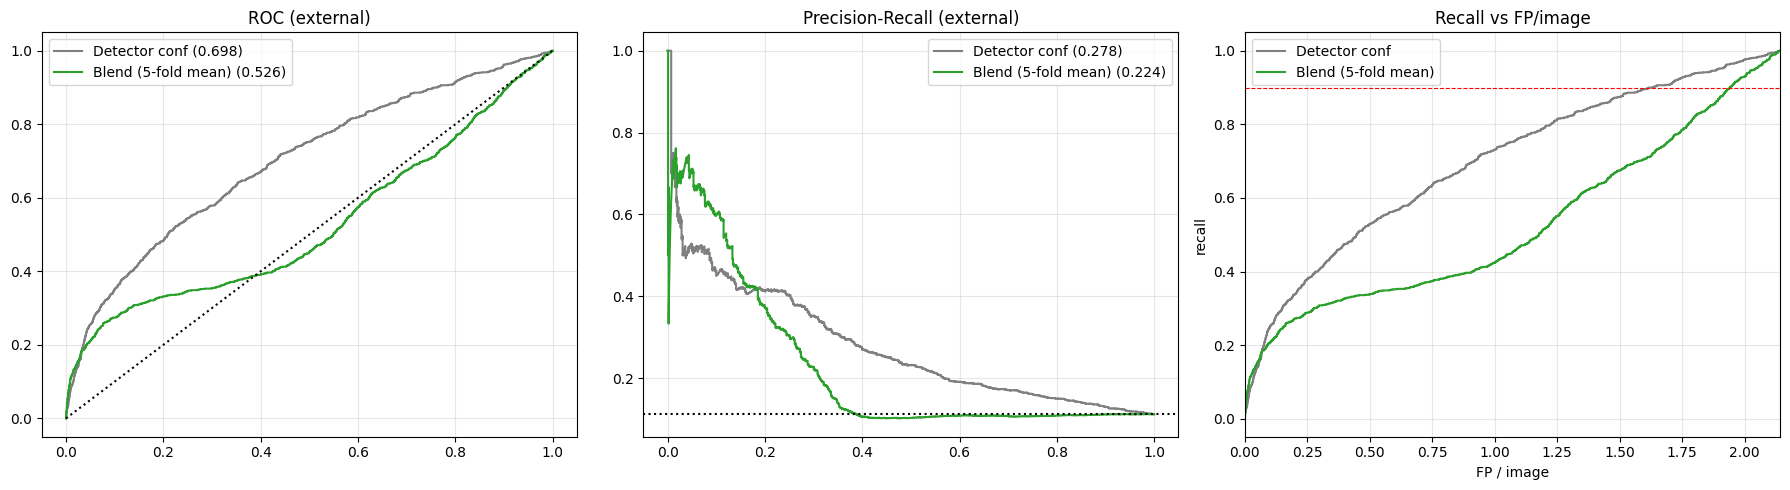

saved -> /kaggle/working/external_vindr


In [29]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for name, s, color in (("Detector conf", df.conf.values, "gray"), ("Blend (5-fold mean)", ensemble["blend"], "tab:green")):
    fpr, tpr, _ = roc_curve(y, s); ax[0].plot(fpr, tpr, color=color, label=f"{name} ({roc_auc_score(y, s):.3f})")
    prec, rec, _ = precision_recall_curve(y, s); ax[1].plot(rec, prec, color=color, label=f"{name} ({average_precision_score(y, s):.3f})")
    order = np.argsort(-s); ax[2].plot(np.cumsum(1 - y[order]) / n_images, np.cumsum(y[order]) / y.sum(), color=color, label=name)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC (external)")
ax[1].axhline(y.mean(), color="k", ls=":"); ax[1].set_title("Precision-Recall (external)")
ax[2].axhline(CFG.target_recall, color="r", ls="--", lw=.8); ax[2].set_xlim(0, base_fp_img)
ax[2].set_xlabel("FP / image"); ax[2].set_ylabel("recall"); ax[2].set_title("Recall vs FP/image")
for a in ax:
    a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "external_results.png"), dpi=200); plt.show()

out = df.copy()
out["verifier_z"], out["lgbm_z"], out["blend_score"] = ensemble["verifier"], ensemble["lgbm"], ensemble["blend"]
out.to_csv(os.path.join(OUT_DIR, "external_predictions.csv"), index=False)
ranking.to_csv(os.path.join(OUT_DIR, "external_ranking.csv"), index=False)
per_class.to_csv(os.path.join(OUT_DIR, "external_per_class.csv"), index=False)
print("saved ->", OUT_DIR)